In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


In [ ]:

from google.colab import files
import zipfile

# Enviar o arquivo ZIP
arquivos = files.upload()

# Extrair o conteúdo
nome_zip = list(arquivos.keys())[0]

with zipfile.ZipFile(nome_zip, 'r') as arquivo:
    arquivo.extractall('dataset')

# Carregar dataset completo
df = pd.read_csv(
    'dataset/Dataset_completo.csv',
    low_memory=False
)

print("Dataset carregado!")


Saving archive (3).zip to archive (3).zip
Dataset carregado!


In [ ]:

# Dimensões do dataset
print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

# Visualizar as primeiras linhas
display(df.head())

# Tipos de dados
print("\nTipos de dados:")
display(df.dtypes)


Quantidade de registros: 368017
Quantidade de colunas: 29


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,dmeansz,trans_depth,res_bdy_len,Stime,Ltime,synack,ackdat,is_sm_ips_ports,ct_state_ttl,Label
0,192.168.56.1,62735.0,192.168.56.102,80.0,TCP,0,0.0,0.0,0.0,0.0,...,0.0,GET,/dav/,0,0,0,0,0,0,0
1,192.168.56.102,80.0,192.168.56.1,62735.0,TCP,0,0.0,0.0,0.0,0.0,...,0.0,GET,/dav/,0,0,0,0,0,0,0
2,192.168.56.1,62735.0,192.168.56.102,80.0,TCP,0,0.0,0.0,0.0,0.0,...,0.0,GET,/icons/blank.gif,0,0,0,0,0,0,0
3,192.168.56.1,62736.0,192.168.56.102,80.0,TCP,0,0.0,0.0,0.0,0.0,...,0.0,GET,/icons/back.gif,0,0,0,0,0,0,0
4,192.168.56.102,80.0,192.168.56.1,62736.0,TCP,0,0.0,0.0,0.0,0.0,...,0.0,GET,/icons/back.gif,0,0,0,0,0,0,0



Tipos de dados:


,0
srcip,object
sport,float64
dstip,object
dsport,float64
proto,object
state,object
dur,float64
sbytes,float64
dbytes,float64
sttl,object


In [ ]:

# Identificar colunas do tipo object
colunas_object = df.select_dtypes(include="object").columns

for coluna in colunas_object:
    print(f"\n===== {coluna} =====")
    print("Quantidade de valores únicos:", df[coluna].nunique())
    print("Exemplos:")
    print(df[coluna].dropna().unique()[:10])



===== srcip =====
Quantidade de valores únicos: 23
Exemplos:
['192.168.56.1' '192.168.56.102' 'fe80:0000:0000:0000:0a00:27ff:fec2:1853'
 '192.168.56.100' 'fe80:0000:0000:0000:1e41:9132:c5af:6169'
 '192.168.56.101' '0.0.0.0' 'fe80:0000:0000:0000:0a00:27ff:fe29:fb1a'
 '0000:0000:0000:0000:0000:0000:0000:0000' '192.168.56.105']

===== dstip =====
Quantidade de valores únicos: 47
Exemplos:
['192.168.56.102' '192.168.56.1' 'ff02:0000:0000:0000:0000:0000:0000:0002'
 '192.168.56.101' '192.168.56.255'
 'ff02:0000:0000:0000:0000:0000:0000:00fb' '224.0.0.251' '224.0.0.252'
 'ff02:0000:0000:0000:0000:0000:0001:0003' '192.168.56.100']

===== proto =====
Quantidade de valores únicos: 14
Exemplos:
['TCP' 'IPv6-ICMP' 'UDP' '0' '17.0' '6.0' 'ICMP' '2.0' '0.0' '1.0']

===== state =====
Quantidade de valores únicos: 4
Exemplos:
['0' 'new' 'closed' 'established']

===== sttl =====
Quantidade de valores únicos: 36
Exemplos:
['0.0' '64.0' '255.0' '1.0' '128.0' '4.0' '0' '128' '64' '255']

===== service ==

In [ ]:

# Quantidade e percentual de valores nulos
nulos = pd.DataFrame({
    "Quantidade": df.isnull().sum(),
    "Percentual (%)": (df.isnull().mean() * 100).round(2)
})

display(nulos.sort_values("Quantidade", ascending=False))


,Quantidade,Percentual (%)
srcip,0,0.0
sport,0,0.0
dstip,0,0.0
dsport,0,0.0
proto,0,0.0
state,0,0.0
dur,0,0.0
sbytes,0,0.0
dbytes,0,0.0
sttl,0,0.0


In [ ]:

duplicados = df.duplicated().sum()

print("Total de registros:", len(df))
print("Registros duplicados:", duplicados)
print("Percentual de duplicatas:",
      round((duplicados / len(df)) * 100, 2), "%")


Total de registros: 368017
Registros duplicados: 5572
Percentual de duplicatas: 1.51 %


### Análise de registros duplicados

O dataset completo possui 368.017 registros e foram identificadas 5.572 linhas duplicadas, correspondendo a aproximadamente 1,51% do conjunto de dados.

A identificação foi realizada utilizando o método `duplicated()` do Pandas, considerando todas as colunas.

Nesta etapa, os registros duplicados foram apenas identificados, sem remoção, para preservar os dados durante a análise exploratória.

Distribuição das classes:


,count
Label,
0,31282
1,336735



Percentual por classe:


,proportion
Label,
0,8.5
1,91.5


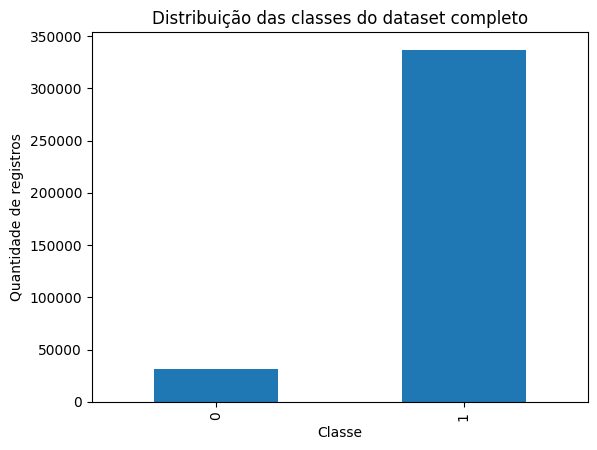

In [ ]:
# Quantidade de registros por classe
print("Distribuição das classes:")
display(df["Label"].value_counts().sort_index())

# Percentual de cada classe
print("\nPercentual por classe:")
display(
    (df["Label"].value_counts(normalize=True).sort_index() * 100).round(2)
)

# Gráfico
df["Label"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribuição das classes do dataset completo",
    xlabel="Classe",
    ylabel="Quantidade de registros"
)

plt.show()

Análise da distribuição das classes: O dataset completo possui 368.017 registros, sendo 336.735 pertencentes à classe 1 (91,5%) e 31.282 à classe 0 (8,5%). Portanto, observa-se um desbalanceamento entre as classes, com predominância da classe 1. Essa característica deve ser considerada nas próximas etapas, principalmente na avaliação dos modelos de classificação.

In [ ]:
df_resumido = pd.read_csv(
    'dataset/Dataset_resumido.csv',
    low_memory=False
)

print("Dimensões:", df_resumido.shape)

print("\nDistribuição das classes:")
display(df_resumido["Label"].value_counts().sort_index())

print("\nPercentual por classe:")
display(
    (df_resumido["Label"].value_counts(normalize=True) * 100).round(2)
)

print("\nTotal de duplicatas:", df_resumido.duplicated().sum())

print("\nValores nulos por coluna:")
display(df_resumido.isnull().sum())

Dimensões: (55826, 25)

Distribuição das classes:


,count
Label,
0,26280
1,29546



Percentual por classe:


,proportion
Label,
1,52.93
0,47.07



Total de duplicatas: 5572

Valores nulos por coluna:


,0
srcip,0
sport,482
dstip,0
dsport,482
proto,0
state,23154
dur,23154
sbytes,22957
dbytes,22957
service,38092


O dataset resumido possui 55.826 registros e 25 colunas. Sua distribuição apresenta 26.280 registros da classe 0 (47,07%) e 29.546 da classe 1 (52,93%), demonstrando maior equilíbrio entre as classes em comparação com o dataset completo. Entretanto, foram identificados 335.224 valores ausentes, distribuídos entre diversas colunas. Também foram encontradas 5.572 duplicatas. Esses fatores precisam ser considerados nas próximas etapas de preparação e treinamento dos modelos.

In [ ]:
print("Duplicatas no dataset completo:")
print(df.duplicated().sum())

print("\nDuplicatas no dataset resumido:")
print(df_resumido.duplicated().sum())

print("\nTotal de valores nulos no dataset resumido:")
print(df_resumido.isnull().sum().sum())

print("\nPercentual de valores nulos:")
total = df_resumido.size
nulos = df_resumido.isnull().sum().sum()

print(f"{(nulos / total) * 100:.2f}%")

Duplicatas no dataset completo:
5572

Duplicatas no dataset resumido:
5572

Total de valores nulos no dataset resumido:
476931

Percentual de valores nulos:
34.17%


Comparação dos resultados: A análise identificou 5.572 registros duplicados em ambas as versões do dataset. O arquivo resumido apresenta 476.931 valores ausentes, correspondendo a 34,17% do total de células. Em relação à distribuição das classes, o dataset completo apresenta predominância da classe 1 (91,5%), enquanto o resumido possui uma distribuição mais equilibrada, com 47,07% da classe 0 e 52,93% da classe 1. Essas diferenças devem ser consideradas na preparação dos dados e na avaliação dos modelos de detecção de ameaças.

In [ ]:
print("Total de valores nulos:")
print(df.isnull().sum().sum())

print("\nPercentual de valores nulos:")
print(
    (df.isnull().sum().sum() / df.size) * 100
)

print("\nQuantidade de colunas:")
print(len(df.columns))

Total de valores nulos:
0

Percentual de valores nulos:
0.0

Quantidade de colunas:
29


### Análise exploratória dos datasets

Foram analisadas duas versões do conjunto de dados de detecção de ameaças: o dataset completo e o dataset resumido.

O dataset completo possui 368.017 registros e 29 colunas. Não foram identificados valores nulos, porém foram encontradas 5.572 duplicatas, correspondendo a aproximadamente 1,51% dos registros. A distribuição das classes apresenta 31.282 registros da classe 0 (8,5%) e 336.735 da classe 1 (91,5%), indicando um desbalanceamento significativo.

O dataset resumido possui 55.826 registros e 25 colunas. Foram identificados 476.931 valores nulos, equivalentes a 34,17% das células, além de 5.572 duplicatas. Sua distribuição apresenta 26.280 registros da classe 0 (47,07%) e 29.546 da classe 1 (52,93%), demonstrando maior equilíbrio entre as classes.

Os resultados mostram diferenças importantes entre as duas versões. O dataset completo apresenta maior quantidade de registros e ausência de valores nulos, enquanto o resumido possui menor quantidade de dados, maior proporção de valores ausentes e melhor equilíbrio entre as classes. Essas características devem ser consideradas nas próximas etapas de preparação e treinamento dos modelos.

In [ ]:
for coluna in df.columns:
    print(f"\nColuna: {coluna}")
    print("Tipo:", df[coluna].dtype)
    print("Exemplos:", df[coluna].dropna().unique()[:5])


Coluna: srcip
Tipo: object
Exemplos: ['192.168.56.1' '192.168.56.102' 'fe80:0000:0000:0000:0a00:27ff:fec2:1853'
 '192.168.56.100' 'fe80:0000:0000:0000:1e41:9132:c5af:6169']

Coluna: sport
Tipo: float64
Exemplos: [62735.    80. 62736.     0.    67.]

Coluna: dstip
Tipo: object
Exemplos: ['192.168.56.102' '192.168.56.1' 'ff02:0000:0000:0000:0000:0000:0000:0002'
 '192.168.56.101' '192.168.56.255']

Coluna: dsport
Tipo: float64
Exemplos: [   80. 62735. 62736.     0.    68.]

Coluna: proto
Tipo: object
Exemplos: ['TCP' 'IPv6-ICMP' 'UDP' '0' '17.0']

Coluna: state
Tipo: object
Exemplos: ['0' 'new' 'closed' 'established']

Coluna: dur
Tipo: float64
Exemplos: [0.0000000e+00 1.9122956e+01 1.9697839e+01 4.4000000e-05 1.0063910e+00]

Coluna: sbytes
Tipo: float64
Exemplos: [   0.   70. 5425. 3505.  543.]

Coluna: dbytes
Tipo: float64
Exemplos: [    0.  5256. 15206.  1549.  1180.]

Coluna: sttl
Tipo: object
Exemplos: ['0.0' '64.0' '255.0' '1.0' '128.0']

Coluna: service
Tipo: object
Exemplos: ['0'

In [ ]:
colunas = [
    "trans_depth",
    "res_bdy_len",
    "synack",
    "ackdat",
    "ct_state_ttl"
]

for coluna in colunas:
    print(f"\n===== {coluna} =====")
    display(df[coluna].value_counts().head(15))


===== trans_depth =====


,count
trans_depth,
0,346784
GET,21115
OPTIONS,67
POST,28
PROPFIND,15
HEAD,5
AHKK,3



===== res_bdy_len =====


,count
res_bdy_len,
0,346784
/,3904
/robots.txt,1265
/twiki/,630
/mutillidae/,536
/twiki/index.php?page=change-log.htm,478
/twiki/index.php?page=installation.php,478
/dvwa/login.php,328
/mutillidae/index.php?page=home.php,128



===== synack =====


,count
synack,
0,170125
True,144783
False,53109



===== ackdat =====


,count
ackdat,
0,186277
False,113526
True,68214



===== ct_state_ttl =====


,count
ct_state_ttl,
0,337547
syn_sent,16152
closed,14125
fin_wait2,128
close_wait,48
established,17


In [ ]:
display(
    df[[
        "trans_depth",
        "res_bdy_len",
        "synack",
        "ackdat",
        "ct_state_ttl",
        "Label"
    ]].sample(15, random_state=42)
)

,trans_depth,res_bdy_len,synack,ackdat,ct_state_ttl,Label
5415,0,0,True,True,closed,0
16195,GET,/,0,0,0,0
23669,GET,/twiki/bin/rename/Sandbox/WebHome?currentwebon...,0,0,0,0
266478,0,0,True,False,0,1
157460,0,0,0,0,0,1
90669,0,0,0,0,0,1
215273,0,0,True,False,0,1
358535,0,0,True,False,0,1
265690,0,0,True,False,0,1
248400,0,0,True,False,0,1


### Investigação das colunas com valores não convencionais

Durante a análise exploratória, foram identificados valores que merecem investigação nas colunas `trans_depth`, `res_bdy_len`, `synack`, `ackdat` e `ct_state_ttl`.

A coluna `trans_depth` apresenta valores como GET, POST e OPTIONS, enquanto `res_bdy_len` contém caminhos de requisições HTTP, como `/robots.txt` e `/dvwa/login.php`. Já as colunas `synack` e `ackdat` apresentam valores booleanos e zero. A coluna `ct_state_ttl` contém estados como `syn_sent`, `closed` e `established`.

Essas observações indicam que os campos podem ter passado por adaptações durante a transformação dos dados. Portanto, seus significados definitivos e suas origens precisam ser confirmados por meio do script de transformação ou da documentação utilizada na geração do dataset.

In [ ]:
colunas = [
    "trans_depth",
    "res_bdy_len",
    "synack",
    "ackdat",
    "ct_state_ttl"
]

for coluna in colunas:
    print(f"\n========== {coluna} ==========")

    tabela = pd.crosstab(
        df[coluna],
        df["Label"],
        normalize="columns"
    ) * 100

    display(tabela.round(2))


========== trans_depth ==========


Label,0,1
trans_depth,,
0,34.68,99.76
AHKK,0.00,0.00
GET,65.32,0.20
HEAD,0.00,0.00
OPTIONS,0.00,0.02
POST,0.00,0.01
PROPFIND,0.00,0.00



========== res_bdy_len ==========


Label,0,1
res_bdy_len,,
/,11.91,0.05
/*,0.01,0.00
/.git/HEAD,0.00,0.00
/?-d+allow_url_include%3dTRUE+-%64+safe_mode%3d0+--define+suhosin.simulation%3d1+--define+disable_functions%3d%22%22+--define+open_basedir%3dnone+-d+auto_prepend_file%3dphp://input+--define+cgi.force_redirect%3dOFf+-%64+cgi.redirect_status_env%3d0+-n,0.00,0.00
/HNAP1,0.00,0.00
/acesso/,0.01,0.00
/dav/,0.20,0.00
/dav/?C=D;O=A,0.04,0.00
/dav/?C=D;O=D,0.06,0.00



========== synack ==========


Label,0,1
synack,,
0,67.37,44.26
False,14.82,14.40
True,17.81,41.34



========== ackdat ==========


Label,0,1
ackdat,,
0,67.37,49.06
False,0.05,33.71
True,32.57,17.23



========== ct_state_ttl ==========


Label,0,1
ct_state_ttl,,
0,82.30,92.60
close_wait,0.02,0.01
closed,17.68,2.55
established,0.00,0.01
fin_wait2,0.00,0.04
syn_sent,0.00,4.80


### Análise das características por classe

Foi realizada uma comparação entre os valores das colunas `trans_depth`, `res_bdy_len` e `ct_state_ttl` em relação à variável `Label`.

Na coluna `trans_depth`, observou-se que o método GET representa 65,32% dos registros da classe 0, enquanto 99,76% dos registros da classe 1 apresentam valor 0.

Na coluna `ct_state_ttl`, o estado `closed` representa 17,68% da classe 0 e 2,55% da classe 1. Já o estado `syn_sent` representa 4,80% da classe 1.

Essas diferenças demonstram que determinadas características apresentam distribuições distintas entre as classes. Entretanto, os resultados são exploratórios e não comprovam, isoladamente, a capacidade de identificar ameaças. A interpretação definitiva dos campos depende da confirmação de sua origem e transformação.

In [ ]:
for coluna in ["synack", "ackdat"]:
    print(f"\n===== {coluna} =====")
    display(
        pd.crosstab(
            df[coluna],
            df["Label"],
            normalize="columns"
        ).mul(100).round(2)
    )


===== synack =====


Label,0,1
synack,,
0,67.37,44.26
False,14.82,14.40
True,17.81,41.34



===== ackdat =====


Label,0,1
ackdat,,
0,67.37,49.06
False,0.05,33.71
True,32.57,17.23


# IDS 5 — Análise Exploratória do Dataset

## 1. Objetivo

Esta etapa tem como objetivo realizar uma análise exploratória dos dados utilizados no projeto de Detecção Inteligente de Ameaças.

Serão analisadas as características dos conjuntos de dados completo e resumido, verificando dimensões, tipos de dados, valores ausentes, registros duplicados, distribuição das classes e comportamento de algumas variáveis.

A análise busca compreender a estrutura dos dados antes da aplicação dos modelos de aprendizado de máquina.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    'dataset/Dataset_completo.csv',
    low_memory=False
)

df_resumido = pd.read_csv(
    'dataset/Dataset_resumido.csv',
    low_memory=False
)

print("Dataset completo:", df.shape)
print("Dataset resumido:", df_resumido.shape)

Dataset completo: (368017, 29)
Dataset resumido: (55826, 25)


In [ ]:
print("Tipos de dados do dataset completo:")
display(df.dtypes)

print("Tipos de dados do dataset resumido:")
display(df_resumido.dtypes)

Tipos de dados do dataset completo:


,0
srcip,object
sport,float64
dstip,object
dsport,float64
proto,object
state,object
dur,float64
sbytes,float64
dbytes,float64
sttl,object


Tipos de dados do dataset resumido:


,0
srcip,object
sport,float64
dstip,object
dsport,float64
proto,object
state,object
dur,float64
sbytes,float64
dbytes,float64
service,object


## 2. Verificação da qualidade dos dados

Nesta etapa, foram analisados os valores ausentes e os registros duplicados dos dois conjuntos de dados.

Essa verificação é importante para identificar possíveis problemas que podem influenciar as análises e o treinamento dos modelos.

In [ ]:
print("DATASET COMPLETO")
print("Valores ausentes:", df.isnull().sum().sum())
print("Registros duplicados:", df.duplicated().sum())

print("\nDATASET RESUMIDO")
print("Valores ausentes:", df_resumido.isnull().sum().sum())
print("Registros duplicados:", df_resumido.duplicated().sum())

DATASET COMPLETO
Valores ausentes: 0
Registros duplicados: 5572

DATASET RESUMIDO
Valores ausentes: 476931
Registros duplicados: 5572


In [ ]:
print("Dataset completo:")
display(df["Label"].value_counts())

print("Percentual:")
display(
    df["Label"].value_counts(normalize=True).mul(100).round(2)
)

print("Dataset resumido:")
display(df_resumido["Label"].value_counts())

print("Percentual:")
display(
    df_resumido["Label"].value_counts(normalize=True).mul(100).round(2)
)

Dataset completo:


,count
Label,
1,336735
0,31282


Percentual:


,proportion
Label,
1,91.5
0,8.5


Dataset resumido:


,count
Label,
1,29546
0,26280


Percentual:


,proportion
Label,
1,52.93
0,47.07


### 3. Distribuição das classes

A análise da variável `Label` mostrou diferenças entre os dois conjuntos de dados.

No dataset completo, a classe 1 representa 91,5% dos registros, enquanto a classe 0 representa apenas 8,5%, indicando um forte desequilíbrio entre as classes.

No dataset resumido, a distribuição é mais equilibrada, com 52,93% dos registros pertencentes à classe 1 e 47,07% à classe 0.

Essa diferença é importante porque o desequilíbrio de classes pode influenciar o treinamento e a avaliação dos modelos de inteligência artificial.

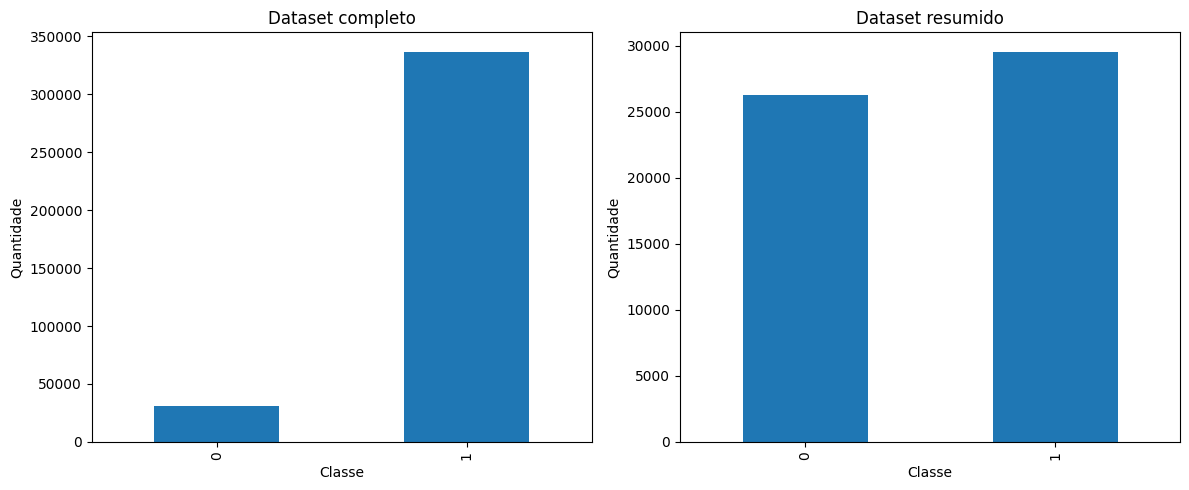

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["Label"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Dataset completo")
axes[0].set_xlabel("Classe")
axes[0].set_ylabel("Quantidade")

df_resumido["Label"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Dataset resumido")
axes[1].set_xlabel("Classe")
axes[1].set_ylabel("Quantidade")

plt.tight_layout()
plt.show()

### 4. Visualização da distribuição das classes

Os gráficos mostram visualmente a distribuição da variável `Label` nos dois conjuntos de dados.

No dataset completo, observa-se uma predominância significativa da classe 1, enquanto a classe 0 possui uma quantidade muito menor de registros.

No dataset resumido, a distribuição entre as duas classes é mais equilibrada. Essa diferença permite observar como a composição dos dados pode influenciar o treinamento e a avaliação dos modelos de detecção de ameaças.

In [ ]:
# Informações das colunas do dataset completo

dicionario_inicial = pd.DataFrame({
    "Coluna": df.columns,
    "Tipo de dado": df.dtypes.astype(str).values,
    "Valores únicos": df.nunique().values,
    "Exemplo": [
        df[col].dropna().iloc[0] if df[col].notna().any() else None
        for col in df.columns
    ]
})

display(dicionario_inicial)

,Coluna,Tipo de dado,Valores únicos,Exemplo
0,srcip,object,23,192.168.56.1
1,sport,float64,17452,62735.0
2,dstip,object,47,192.168.56.102
3,dsport,float64,8593,80.0
4,proto,object,14,TCP
5,state,object,4,0
6,dur,float64,20953,0.0
7,sbytes,float64,1652,0.0
8,dbytes,float64,3266,0.0
9,sttl,object,36,0.0


In [ ]:
dicionario = {
    "srcip": "Endereço IP de origem",
    "sport": "Porta de origem",
    "dstip": "Endereço IP de destino",
    "dsport": "Porta de destino",
    "proto": "Protocolo de comunicação",
    "state": "Estado da conexão",
    "dur": "Duração da comunicação",
    "sbytes": "Bytes enviados pela origem",
    "dbytes": "Bytes enviados pelo destino",
    "sttl": "TTL dos pacotes de origem",
    "service": "Serviço de rede utilizado",
    "Sload": "Taxa de transmissão da origem",
    "Dload": "Taxa de transmissão do destino",
    "Spkts": "Pacotes enviados pela origem",
    "Dpkts": "Pacotes enviados pelo destino",
    "swin": "Janela TCP da origem",
    "stcpb": "Número de sequência TCP da origem",
    "dtcpb": "Número de sequência TCP do destino",
    "smeansz": "Tamanho médio dos pacotes da origem",
    "dmeansz": "Tamanho médio dos pacotes do destino",
    "trans_depth": "Profundidade da transação HTTP (confirmar)",
    "res_bdy_len": "Comprimento do corpo da resposta (confirmar)",
    "Stime": "Horário de início do fluxo",
    "Ltime": "Horário do último registro do fluxo",
    "synack": "Intervalo SYN até SYN-ACK (confirmar)",
    "ackdat": "Intervalo SYN-ACK até ACK (confirmar)",
    "is_sm_ips_ports": "Indicador de igualdade entre IPs e portas",
    "ct_state_ttl": "Atributo relacionado ao estado e TTL (confirmar)",
    "Label": "Classe de classificação"
}

tabela_dicionario = pd.DataFrame({
    "Coluna": df.columns,
    "Descrição": [dicionario[col] for col in df.columns]
})

display(tabela_dicionario)

,Coluna,Descrição
0,srcip,Endereço IP de origem
1,sport,Porta de origem
2,dstip,Endereço IP de destino
3,dsport,Porta de destino
4,proto,Protocolo de comunicação
5,state,Estado da conexão
6,dur,Duração da comunicação
7,sbytes,Bytes enviados pela origem
8,dbytes,Bytes enviados pelo destino
9,sttl,TTL dos pacotes de origem


In [ ]:
tabela_dicionario = pd.DataFrame({
    "Coluna": df.columns,
    "Descrição": [dicionario[col] for col in df.columns]
})

display(tabela_dicionario)

,Coluna,Descrição
0,srcip,Endereço IP de origem
1,sport,Porta de origem
2,dstip,Endereço IP de destino
3,dsport,Porta de destino
4,proto,Protocolo de comunicação
5,state,Estado da conexão
6,dur,Duração da comunicação
7,sbytes,Bytes enviados pela origem
8,dbytes,Bytes enviados pelo destino
9,sttl,TTL dos pacotes de origem


### 5. Dicionário de dados

Foi elaborado um dicionário contendo as 29 colunas do dataset completo, identificando a finalidade de cada atributo.

As variáveis representam informações relacionadas aos endereços IP, portas, protocolos, estados das conexões, quantidade de pacotes, volume de dados e características do tráfego de rede.

Também foram identificados alguns atributos cujos valores observados precisam de confirmação, especialmente aqueles relacionados às transações HTTP e ao estabelecimento de conexões TCP.

In [ ]:
# Quantidade de valores ausentes por coluna
ausentes = df_resumido.isnull().sum()

# Percentual de valores ausentes
percentual = (ausentes / len(df_resumido)) * 100

tabela_ausentes = pd.DataFrame({
    "Valores ausentes": ausentes,
    "Percentual (%)": percentual.round(2)
})

display(
    tabela_ausentes.sort_values(
        by="Valores ausentes",
        ascending=False
    )
)

,Valores ausentes,Percentual (%)
ackdat,41508,74.35
service,38092,68.23
res_bdy_len,34593,61.97
trans_depth,34593,61.97
synack,25356,45.42
ct_state_ttl,25356,45.42
Dload,23154,41.48
state,23154,41.48
dur,23154,41.48
Ltime,23154,41.48


### 6. Análise de valores ausentes

Nesta etapa, foi realizada uma verificação dos valores ausentes nas colunas do dataset resumido.

O objetivo é identificar quais atributos apresentam dados incompletos e verificar a proporção dessas ausências, permitindo avaliar possíveis impactos nas etapas posteriores de processamento e treinamento dos modelos.

### 6.1. Interpretação dos valores ausentes

A análise identificou 476.931 valores ausentes no dataset resumido, representando aproximadamente 34,17% do total de células.

As colunas com maior quantidade de ausências foram `ackdat`, com 74,35%, `service`, com 68,23%, e `res_bdy_len` e `trans_depth`, ambas com 61,97%.

Também foram identificadas colunas sem valores ausentes, como `srcip`, `dstip`, `proto` e `Label`.

Esses resultados demonstram que o dataset resumido possui informações incompletas em diversos atributos. Portanto, será necessário considerar essas ausências nas próximas etapas de preparação dos dados.

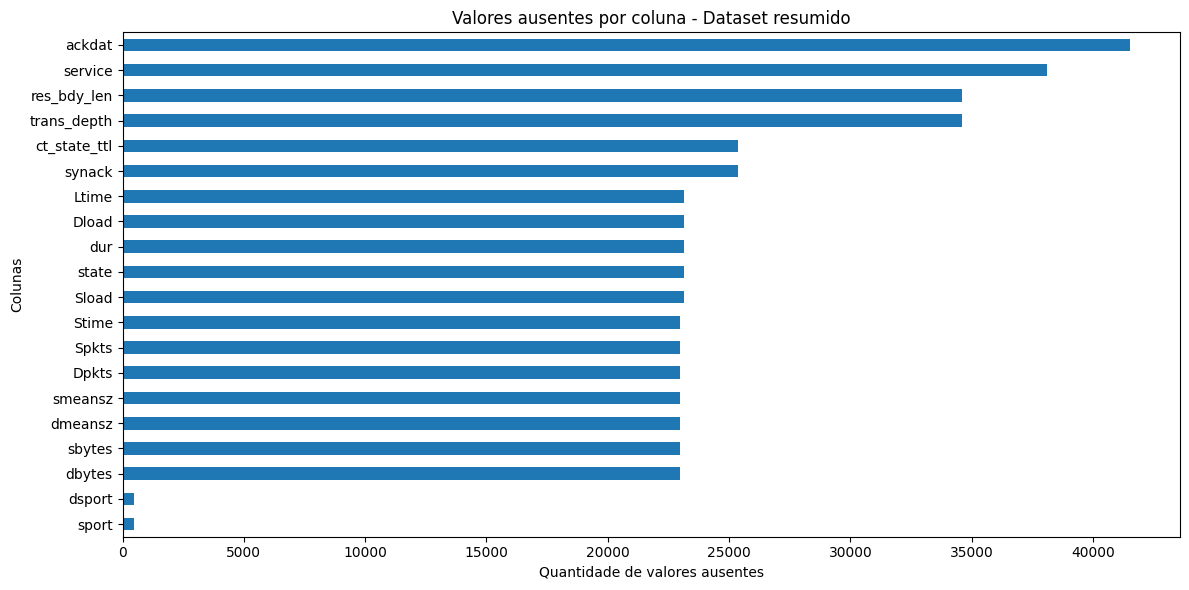

In [ ]:
plt.figure(figsize=(12, 6))

ausentes[ausentes > 0].sort_values().plot(
    kind="barh"
)

plt.title("Valores ausentes por coluna - Dataset resumido")
plt.xlabel("Quantidade de valores ausentes")
plt.ylabel("Colunas")
plt.tight_layout()
plt.show()

In [ ]:
print("DATASET COMPLETO")
print("Registros duplicados:", df.duplicated().sum())

print("\nDATASET RESUMIDO")
print("Registros duplicados:", df_resumido.duplicated().sum())

DATASET COMPLETO
Registros duplicados: 5572

DATASET RESUMIDO
Registros duplicados: 5572


### 7. Análise de registros duplicados

A verificação identificou 5.572 registros duplicados tanto no dataset completo quanto no resumido.

Esses registros representam ocorrências repetidas em relação a linhas anteriores. A identificação é importante para avaliar a qualidade dos dados e evitar possíveis impactos nas etapas de treinamento dos modelos.

Nesta etapa, os registros duplicados foram apenas identificados, sem exclusão.

In [ ]:
for coluna in ["proto", "state", "service"]:
    print(f"\nDistribuição da coluna: {coluna}")
    display(df[coluna].value_counts().head(10))


Distribuição da coluna: proto


,count
proto,
6.0,154361
1.0,132372
TCP,53004
6,13061
0.0,5521
17.0,3773
0,2903
UDP,2340
IPv6-ICMP,472



Distribuição da coluna: state


,count
state,
0,335345
new,18200
closed,14125
established,347



Distribuição da coluna: service


,count
service,
0,350283
http,15651
failed,1567
dhcp,154
ftp,154
tls,67
ntp,49
dns,26
ssh,23


### 8. Distribuição das variáveis categóricas

Foram analisadas as distribuições das colunas `proto`, `state` e `service` do dataset completo.

Na coluna `proto`, foram encontrados diferentes valores numéricos e textuais, com predominância dos valores 6.0 e 1.0.

Na coluna `state`, o valor 0 apresentou a maior frequência, seguido pelos estados new e closed.

Na coluna `service`, o valor 0 também foi predominante, enquanto serviços como HTTP, DHCP, FTP, TLS e DNS apareceram em menores quantidades.

A análise identificou diferentes representações dentro das variáveis categóricas, indicando a necessidade de investigar e padronizar esses valores durante a preparação dos dados.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sport,368017.0,26218.171810,2.757580e+04,0.0,0.0,5601.0,54131.0,6.553500e+04
dsport,368017.0,8865.013247,1.934177e+04,0.0,0.0,53.0,1039.0,6.549800e+04
dur,368017.0,1.192641,4.542456e+01,0.0,0.0,0.0,0.0,2.581518e+04
sbytes,368017.0,122.219993,1.477683e+04,0.0,0.0,0.0,0.0,7.603321e+06
dbytes,368017.0,2346.512224,5.158371e+05,0.0,0.0,0.0,0.0,2.118969e+08
Sload,368017.0,4427.509780,2.073433e+05,0.0,0.0,0.0,0.0,2.088462e+07
Dload,368017.0,1398.492084,6.111855e+04,0.0,0.0,0.0,0.0,1.057143e+07
Spkts,368017.0,2.155077,1.820463e+02,0.0,1.0,1.0,1.0,6.786000e+04
Dpkts,368017.0,1.911224,3.721714e+02,0.0,0.0,0.0,0.0,1.418460e+05
swin,368017.0,66326.138151,3.025837e+05,0.0,0.0,0.0,64240.0,2.102272e+06


### 9. Estatísticas descritivas das variáveis numéricas

Foram calculadas estatísticas descritivas das variáveis numéricas, incluindo média, desvio padrão, valores mínimos, máximos e quartis.

A análise identificou diferenças significativas entre as escalas das variáveis. Alguns atributos, como `dbytes`, `Sload` e `dtcpb`, apresentam valores máximos bastante elevados em comparação com suas medianas.

Também foi observado que a coluna `is_sm_ips_ports` apresenta apenas valores iguais a zero, não possuindo variação no conjunto analisado.

Essas características indicam a necessidade de investigar possíveis valores extremos e avaliar a distribuição das variáveis antes da aplicação dos modelos de aprendizado de máquina.

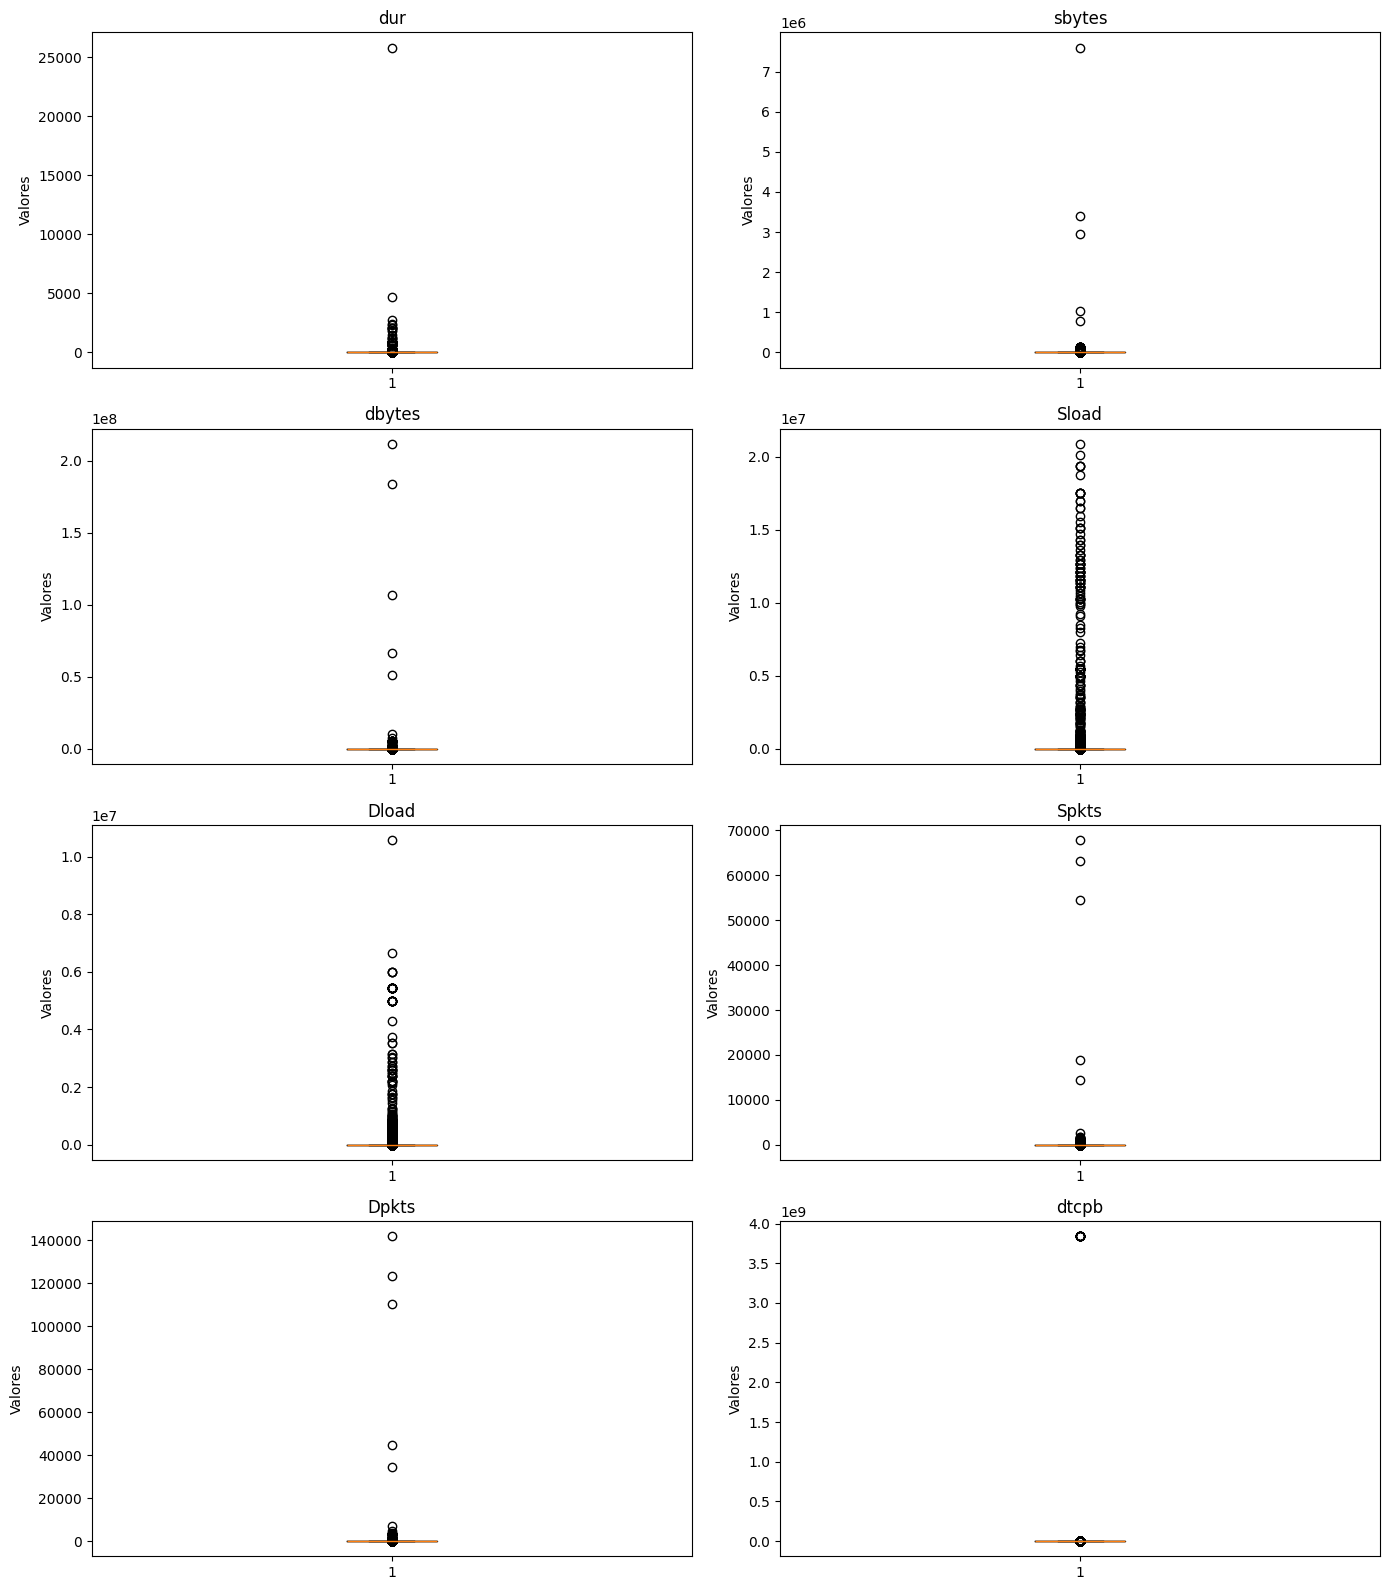

In [ ]:
colunas = ["dur", "sbytes", "dbytes", "Sload", "Dload", "Spkts", "Dpkts", "dtcpb"]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for coluna, ax in zip(colunas, axes.flatten()):
    ax.boxplot(df[coluna].dropna())
    ax.set_title(coluna)
    ax.set_ylabel("Valores")

plt.tight_layout()
plt.show()

In [ ]:
colunas = [
    "dur", "sbytes", "dbytes",
    "Sload", "Dload", "Spkts",
    "Dpkts", "swin", "smeansz", "dmeansz"
]

comparacao = df.groupby("Label")[colunas].mean().T

display(comparacao.round(2))

Label,0,1
dur,2.96,1.03
sbytes,699.97,68.55
dbytes,7513.23,1866.53
Sload,7089.98,4180.17
Dload,658.56,1467.23
Spkts,5.36,1.86
Dpkts,7.87,1.36
swin,114962.44,61807.92
smeansz,121.02,16.63
dmeansz,123.14,2.17


### 10. Relação entre as variáveis numéricas e a classe

Foi realizada uma comparação das médias de dez variáveis numéricas, separando os registros pelas classes 0 e 1.

Os resultados mostraram que a classe 0 apresentou médias superiores em nove das dez variáveis analisadas. A única exceção foi `Dload`, que apresentou média maior na classe 1.

As diferenças foram especialmente expressivas nas variáveis `sbytes`, `dbytes`, `Spkts`, `Dpkts`, `smeansz` e `dmeansz`.

Essa análise demonstra que as classes possuem características distintas em relação ao tráfego de rede. Entretanto, as médias isoladamente não são suficientes para determinar quais variáveis são mais importantes para identificar ameaças.

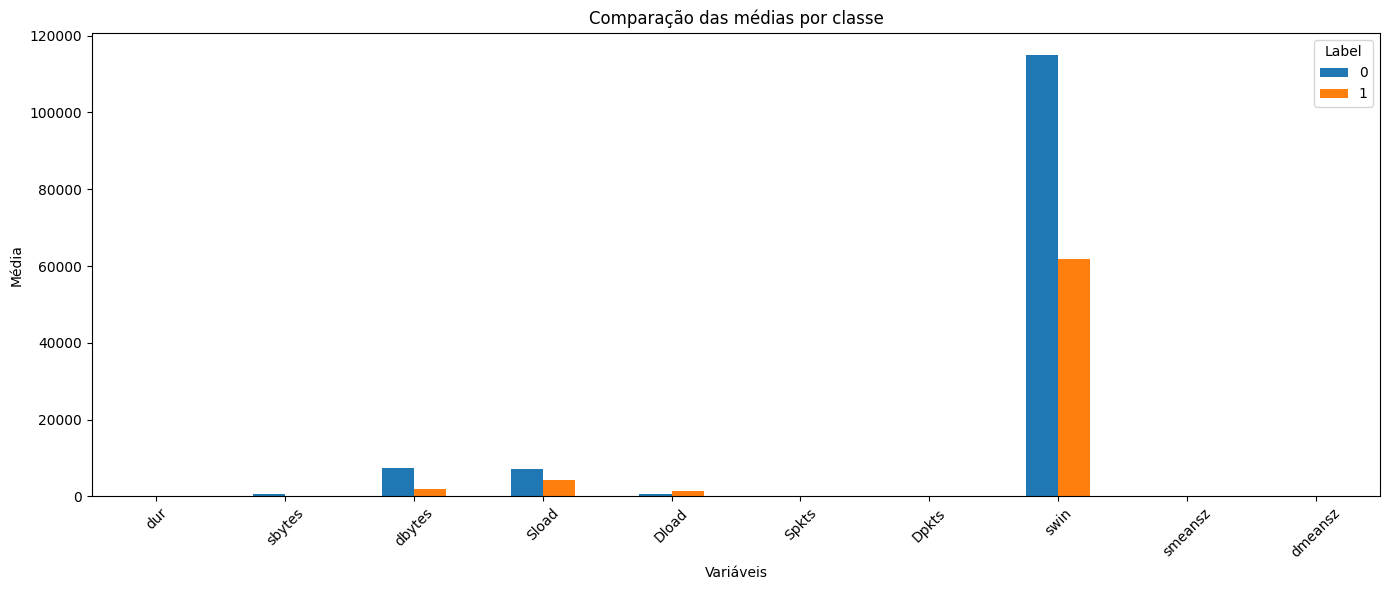

In [ ]:
comparacao.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Comparação das médias por classe")
plt.xlabel("Variáveis")
plt.ylabel("Média")
plt.xticks(rotation=45)
plt.legend(title="Label")
plt.tight_layout()
plt.show()

## 11. Conclusão da análise exploratória

A análise exploratória permitiu conhecer a estrutura e as características dos datasets completo e resumido utilizados no projeto.

Foram identificadas diferenças na distribuição das classes, valores ausentes, registros duplicados e variações nas características do tráfego de rede.

O dataset completo apresenta forte desequilíbrio entre as classes, enquanto o resumido possui uma distribuição mais equilibrada.

Também foram observadas diferenças entre as médias das variáveis numéricas quando comparadas por classe, indicando padrões distintos nos registros.

Esses resultados fornecem uma base para as próximas etapas do projeto, especialmente a preparação dos dados e o desenvolvimento de modelos de aprendizado de máquina para detecção de ameaças.

In [ ]:

# ============================================================
# PROJETO IDS - ANÁLISE EXPLORATÓRIA DOS DATASETS
# Dataset Completo e Dataset Resumido
# ============================================================

import pandas as pd
import numpy as np
import os
import glob
import zipfile
from google.colab import files
from IPython.display import display

# ------------------------------------------------------------
# 1. ENVIAR OS ARQUIVOS
# ------------------------------------------------------------

print("Envie o ZIP ou os dois arquivos CSV do projeto.")
uploaded = files.upload()

# Extrair arquivos ZIP, caso tenha sido enviado
for nome in uploaded.keys():
    if nome.lower().endswith(".zip"):
        with zipfile.ZipFile(nome, "r") as arquivo_zip:
            arquivo_zip.extractall("/content/datasets")

# Procurar arquivos CSV
arquivos_csv = glob.glob("/content/*.csv")
arquivos_csv += glob.glob("/content/datasets/**/*.csv", recursive=True)

# Evitar arquivos repetidos na lista
arquivos_csv = list(set(arquivos_csv))

def localizar_arquivo(palavras):
    for caminho in arquivos_csv:
        nome = os.path.basename(caminho).lower()
        if all(palavra in nome for palavra in palavras):
            return caminho
    return None

arquivo_completo = localizar_arquivo(["completo"])
arquivo_resumido = localizar_arquivo(["resumido"])

if arquivo_completo is None or arquivo_resumido is None:
    print("Arquivos CSV encontrados:")
    for caminho in arquivos_csv:
        print("-", caminho)
    raise FileNotFoundError(
        "Não encontrei os dois arquivos. "
        "Verifique se os nomes contêm 'completo' e 'resumido'."
    )

# ------------------------------------------------------------
# 2. CARREGAR OS DATASETS
# ------------------------------------------------------------

def carregar_csv(caminho):
    try:
        df = pd.read_csv(
            caminho,
            sep=None,
            engine="python",
            encoding="utf-8-sig"
        )
    except UnicodeDecodeError:
        df = pd.read_csv(
            caminho,
            sep=None,
            engine="python",
            encoding="latin1"
        )

    return df
df_completo = carregar_csv(arquivo_completo)
df_resumido = carregar_csv(arquivo_resumido)

# Limpar espaços dos nomes das colunas
df_completo.columns = df_completo.columns.astype(str).str.strip()
df_resumido.columns = df_resumido.columns.astype(str).str.strip()

datasets = {
    "Dataset Completo": df_completo,
    "Dataset Resumido": df_resumido
}

print("\nARQUIVOS CARREGADOS COM SUCESSO!")

# ------------------------------------------------------------
# 3. DICIONÁRIO DE DESCRIÇÃO DAS COLUNAS
# ------------------------------------------------------------

descricoes = {
    "srcip": "Endereço IP de origem da comunicação.",
    "sport": "Porta de origem da comunicação.",
    "dstip": "Endereço IP de destino da comunicação.",
    "dsport": "Porta de destino da comunicação.",
    "proto": "Protocolo utilizado na comunicação de rede.",
    "state": "Estado ou situação da conexão.",
    "dur": "Duração da comunicação ou fluxo.",
    "sbytes": "Quantidade de bytes enviados pela origem.",
    "dbytes": "Quantidade de bytes enviados pelo destino.",
    "sttl": "Valor do TTL dos pacotes enviados pela origem.",
    "service": "Serviço de rede associado à comunicação.",
    "Sload": "Taxa de envio de dados da origem.",
    "Dload": "Taxa de envio de dados do destino.",
    "Spkts": "Quantidade de pacotes enviados pela origem.",
    "Dpkts": "Quantidade de pacotes enviados pelo destino.",
    "swin": "Valor da janela TCP da origem.",
    "stcpb": "Valor inicial da sequência de bytes TCP da origem.",
    "dtcpb": "Valor inicial da sequência de bytes TCP do destino.",
    "smeansz": "Tamanho médio dos pacotes enviados pela origem.",
    "dmeansz": "Tamanho médio dos pacotes enviados pelo destino.",
    "trans_depth": "Profundidade de transação observada na comunicação.",
    "res_bdy_len": "Comprimento do corpo da resposta.",
    "Stime": "Data ou instante de início do registro ou fluxo.",
    "Ltime": "Data ou instante associado ao último registro do fluxo.",
    "synack": "Tempo relacionado às etapas SYN e ACK da conexão TCP.",
    "ackdat": "Tempo entre o recebimento do SYN-ACK e o ACK final.",
    "is_sm_ips_ports": "Indicador relacionado à igualdade entre IPs e portas de origem e destino.",
    "ct_state_ttl": "Contagem relacionada à combinação de estado da conexão e TTL.",
    "Label": "Classe do registro: 0 representa tráfego benigno e 1 representa atividade maliciosa."
}

# ------------------------------------------------------------
# 4. FUNÇÃO DE ANÁLISE EXPLORATÓRIA
# ------------------------------------------------------------

resultados_info = []
resultados_classes = []
resultados_nulos = []
resultados_dicionarios = []

def analisar_dataset(nome, df):

    print("\n" + "=" * 65)
    print(nome.upper())
    print("=" * 65)

    # Dimensão
    linhas, colunas = df.shape

    # Valores ausentes
    total_nulos = int(df.isnull().sum().sum())
    percentual_nulos = (total_nulos / df.size * 100) if df.size else 0

    # Duplicatas
    duplicatas = int(df.duplicated().sum())
    percentual_duplicatas = (
        duplicatas / linhas * 100 if linhas else 0
    )

    print(f"\nQuantidade de linhas: {linhas:,}")
    print(f"Quantidade de colunas: {colunas}")
    print(f"Total de células vazias: {total_nulos:,}")
    print(f"Percentual de células vazias: {percentual_nulos:.2f}%")
    print(f"Linhas duplicadas: {duplicatas:,}")
    print(f"Percentual de duplicatas: {percentual_duplicatas:.2f}%")

    resultados_info.append({
        "Dataset": nome,
        "Linhas": linhas,
        "Colunas": colunas,
        "Valores ausentes": total_nulos,
        "Percentual de células ausentes": round(percentual_nulos, 2),
        "Linhas duplicadas": duplicatas,
        "Percentual de duplicatas": round(percentual_duplicatas, 2)
    })

    # --------------------------------------------------------
    # DISTRIBUIÇÃO DAS CLASSES
    # --------------------------------------------------------

    coluna_label = next(
        (c for c in df.columns if c.lower() == "label"),
        None
    )

    if coluna_label:
        print("\nDISTRIBUIÇÃO DAS CLASSES:")

        contagem = df[coluna_label].value_counts(dropna=False)
        percentual = df[coluna_label].value_counts(
            normalize=True, dropna=False
        ) * 100

        tabela_classes = pd.DataFrame({
            "Quantidade": contagem,
            "Percentual": percentual.round(2)
        })

        display(tabela_classes)

        for classe, quantidade in contagem.items():
            resultados_classes.append({
                "Dataset": nome,
                "Classe": classe,
                "Quantidade": int(quantidade),
                "Percentual": round(float(percentual[classe]), 2)
            })
    else:
        print("\nA coluna Label não foi encontrada.")

    # --------------------------------------------------------
    # VALORES AUSENTES POR COLUNA
    # --------------------------------------------------------

    print("\nVALORES AUSENTES POR COLUNA:")

    tabela_nulos = pd.DataFrame({
        "Coluna": df.columns,
        "Valores ausentes": df.isnull().sum().values,
        "Percentual (%)": (
            df.isnull().mean().values * 100
        ).round(2)
    })

    tabela_nulos = tabela_nulos.sort_values(
        "Valores ausentes", ascending=False
    )

    display(tabela_nulos)

    for _, linha in tabela_nulos.iterrows():
        resultados_nulos.append({
            "Dataset": nome,
            "Coluna": linha["Coluna"],
            "Valores ausentes": int(linha["Valores ausentes"]),
            "Percentual (%)": linha["Percentual (%)"]
        })

    # --------------------------------------------------------
    # DICIONÁRIO DE TODAS AS COLUNAS
    # --------------------------------------------------------

    print("\nDICIONÁRIO DE DADOS:")

    dicionario = []

    for coluna in df.columns:

        descricao = descricoes.get(
            coluna,
            "Atributo presente no dataset. "
            "Significado específico não documentado nas fontes consultadas."
        )

        exemplos = df[coluna].dropna().astype(str).unique()[:3]

        dicionario.append({
            "Dataset": nome,
            "Coluna": coluna,
            "Tipo de dado": str(df[coluna].dtype),
            "Descrição": descricao,
            "Valores únicos": int(df[coluna].nunique(dropna=True)),
            "Valores ausentes": int(df[coluna].isnull().sum()),
            "Exemplos": ", ".join(exemplos)
        })

    tabela_dicionario = pd.DataFrame(dicionario)
    display(tabela_dicionario)

    resultados_dicionarios.extend(dicionario)

    # --------------------------------------------------------
    # VISUALIZAÇÃO GERAL
    # --------------------------------------------------------

    print("\nPRIMEIRAS CINCO LINHAS:")
    display(df.head())

# ------------------------------------------------------------
# 5. EXECUTAR A ANÁLISE NOS DOIS DATASETS
# ------------------------------------------------------------

for nome, df in datasets.items():
    analisar_dataset(nome, df)

# ------------------------------------------------------------
# 6. COMPARAÇÃO ENTRE OS DATASETS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("COMPARAÇÃO GERAL DOS DATASETS")
print("=" * 65)

tabela_comparacao = pd.DataFrame(resultados_info)
display(tabela_comparacao)

# ------------------------------------------------------------
# 7. EXPORTAR RESULTADOS PARA EXCEL
# ------------------------------------------------------------

arquivo_saida = "/content/Analise_Exploratoria_IDS.xlsx"

with pd.ExcelWriter(arquivo_saida, engine="openpyxl") as writer:

    pd.DataFrame(resultados_info).to_excel(
        writer, sheet_name="Resumo", index=False
    )

    pd.DataFrame(resultados_classes).to_excel(
        writer, sheet_name="Distribuicao_Classes", index=False
    )

    pd.DataFrame(resultados_nulos).to_excel(
        writer, sheet_name="Valores_Ausentes", index=False
    )

    pd.DataFrame(resultados_dicionarios).to_excel(
        writer, sheet_name="Dicionario_Colunas", index=False
    )

print("\nANÁLISE CONCLUÍDA!")
print("Arquivo Excel gerado:", arquivo_saida)

files.download(arquivo_saida)


Envie o ZIP ou os dois arquivos CSV do projeto.


Saving archive (3).zip to archive (3) (1).zip

ARQUIVOS CARREGADOS COM SUCESSO!

DATASET COMPLETO

Quantidade de linhas: 368,017
Quantidade de colunas: 29
Total de células vazias: 0
Percentual de células vazias: 0.00%
Linhas duplicadas: 5,572
Percentual de duplicatas: 1.51%

DISTRIBUIÇÃO DAS CLASSES:


,Quantidade,Percentual
Label,,
1,336735,91.5
0,31282,8.5



VALORES AUSENTES POR COLUNA:


,Coluna,Valores ausentes,Percentual (%)
0,srcip,0,0.0
1,sport,0,0.0
2,dstip,0,0.0
3,dsport,0,0.0
4,proto,0,0.0
5,state,0,0.0
6,dur,0,0.0
7,sbytes,0,0.0
8,dbytes,0,0.0
9,sttl,0,0.0



DICIONÁRIO DE DADOS:


... (12 outputs left out)

,Dataset,Linhas,Colunas,Valores ausentes,Percentual de células ausentes,Linhas duplicadas,Percentual de duplicatas
0,Dataset Completo,368017,29,0,0.00,5572,1.51
1,Dataset Resumido,55826,25,476931,34.17,5572,9.98



ANÁLISE CONCLUÍDA!
Arquivo Excel gerado: /content/Analise_Exploratoria_IDS.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download('/content/Analise_Exploratoria_IDS.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
import os

arquivo_zip = "/content/archive (3).zip"

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    for nome in zip_ref.namelist():
        print(nome)

Dataset_completo.csv
Dataset_resumido.csv
